# NYC Taxi Rides: Fares, Duration, Payment and Demand Patterns

**A question-driven analysis of 6,433 New York City taxi rides (March 2019)**

---

## Project Overview

Every taxi ride generates a small trail of data: when it started and ended, how far it went, what it cost, how it was paid for, and where it began and finished. This project turns that trail into answers about how fares are built, what drives ride duration and cost, how payment method changes what the data shows, and when and where demand concentrates.

**Business questions**

1. How does the total fare differ by payment method, and is that difference real or a recording artefact?
2. How well do ride duration and distance predict the fare?
3. Do the fare-duration relationship and pricing differ by payment method or taxi colour?
4. How do passengers tip, and does tipping differ between yellow and green taxis?
5. When is demand highest, and how do speeds and fares change through the day?
6. Which boroughs, zones and routes generate the longest and most expensive rides?
7. How concentrated is revenue: which rides account for a disproportionate share of total fares?

**Dataset:** seaborn's built-in `taxis` dataset (6,433 rides, 14 columns; pickups from 28 Feb to 31 Mar 2019).
**Tools:** pandas, NumPy, Matplotlib, Seaborn, SciPy, statsmodels.

**Notebook flow:** Dataset Understanding → Data Quality → Data Preparation → Exploratory Analysis → Question-Driven Analysis → Key Insights → Conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

# One colour per category, reused in every chart
payment_palette = {"cash": "#4c72b0", "credit card": "#dd8452"}
taxi_palette = {"yellow": "#f2b705", "green": "#3a9d5d"}

## 1. Dataset Understanding

In [2]:
raw = sns.load_dataset("taxis")
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 6,433 | Columns: 14


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.00,2.15,0.00,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.00,0.00,0.00,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.50,2.36,0.00,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.00,6.15,0.00,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.00,1.10,0.00,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


**Data dictionary**

| Column | Meaning |
|---|---|
| `pickup`, `dropoff` | Start and end timestamps of the ride |
| `passengers` | Number of passengers |
| `distance` | Trip distance in miles |
| `fare` | Metered fare in USD (before tip, tolls and fixed surcharges) |
| `tip` | Tip in USD |
| `tolls` | Tolls paid in USD |
| `total` | Total amount charged in USD |
| `color` | Taxi type: `yellow` or `green` |
| `payment` | Payment method: `cash` or `credit card` |
| `pickup_zone`, `dropoff_zone` | NYC taxi zone of pickup and drop-off |
| `pickup_borough`, `dropoff_borough` | Borough of pickup and drop-off |

In [3]:
raw.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
pickup,6433,NaN,NaN,NaN,2019-03-16 08:31:28.514223,2019-02-28 23:29:03,2019-03-08 15:50:34,2019-03-15 21:46:58,2019-03-23 17:41:38,2019-03-31 23:43:45,NaN
dropoff,6433,NaN,NaN,NaN,2019-03-16 08:45:49.491216,2019-02-28 23:32:35,2019-03-08 16:12:51,2019-03-15 22:06:44,2019-03-23 17:51:56,2019-04-01 00:13:58,NaN
passengers,"6,433.00",NaN,NaN,NaN,1.54,0.00,1.00,1.00,2.00,6.00,1.20
distance,"6,433.00",NaN,NaN,NaN,3.02,0.00,0.98,1.64,3.21,36.70,3.83
fare,"6,433.00",NaN,NaN,NaN,13.09,1.00,6.50,9.50,15.00,150.00,11.55
tip,"6,433.00",NaN,NaN,NaN,1.98,0.00,0.00,1.70,2.80,33.20,2.45
tolls,"6,433.00",NaN,NaN,NaN,0.33,0.00,0.00,0.00,0.00,24.02,1.42
total,"6,433.00",NaN,NaN,NaN,18.52,1.30,10.80,14.16,20.30,174.82,13.82
color,6433,2,yellow,5451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment,6389,2,credit card,4577,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Quality

In [4]:
missing = raw.isna().sum()
missing = pd.DataFrame({"missing": missing, "% of rows": missing / len(raw) * 100}).loc[lambda d: d["missing"] > 0]
print(f"Exact duplicate rows: {raw.duplicated().sum()}")
missing

Exact duplicate rows: 0


,missing,% of rows
payment,44,0.68
pickup_zone,26,0.40
dropoff_zone,45,0.70
pickup_borough,26,0.40
dropoff_borough,45,0.70


In [5]:
work = raw.copy()
work["duration_min"] = (work["dropoff"] - work["pickup"]).dt.total_seconds() / 60
work["speed_mph"] = (work["distance"] / (work["duration_min"] / 60)).replace([np.inf, -np.inf], np.nan)

flags = pd.DataFrame({
    "duration under 1 minute": work["duration_min"] < 1,
    "zero distance": work["distance"] <= 0,
    "speed above 80 mph": work["speed_mph"] > 80,
})
flags["any issue"] = flags.any(axis=1)

print("Rides flagged as implausible:")
print(flags.sum().to_string())
print(f"\nUnits removed: {flags['any issue'].sum()} of {len(work):,} ({flags['any issue'].mean():.2%})")

work.loc[flags["any issue"], ["pickup", "duration_min", "distance", "speed_mph", "fare", "total"]].sort_values("fare", ascending=False).head(8)

Rides flagged as implausible:
duration under 1 minute    72
zero distance              51
speed above 80 mph         11
any issue                  84

Units removed: 84 of 6,433 (1.31%)


,pickup,duration_min,distance,speed_mph,fare,total
622,2019-03-12 19:52:36,0.32,0.00,0.00,120.00,166.00
3644,2019-03-19 23:30:50,1.72,0.00,0.00,103.00,123.95
42,2019-03-30 23:59:14,0.05,0.00,0.00,80.00,100.38
1690,2019-03-22 06:24:14,0.00,0.00,NaN,72.00,72.00
6393,2019-03-10 18:33:13,59.42,0.00,0.00,71.20,72.00
2387,2019-03-28 15:58:52,0.55,1.80,196.36,69.06,90.16
3571,2019-03-22 16:47:41,0.15,0.81,324.00,66.00,66.80
3241,2019-03-24 17:19:27,0.03,0.34,612.00,65.00,78.36


In [6]:
# Do the money columns add up?  total = fare + tip + tolls + (untracked fixed fees)
gap = (work["total"] - work["fare"] - work["tip"] - work["tolls"]).round(2)
print("total - (fare + tip + tolls):")
print(gap.describe().round(2).to_string())

# How is the tip recorded by payment method?
print("\nShare of rides with a zero tip, by payment method:")
print(work.groupby("payment", dropna=False)["tip"].apply(lambda s: (s == 0).mean()).map("{:.1%}".format).to_string())

total - (fare + tip + tolls):
count   6,433.00
mean        3.12
std         1.14
min         0.00
25%         3.30
50%         3.30
75%         3.80
max         7.80

Share of rides with a zero tip, by payment method:
payment
cash           100.0%
credit card      9.9%
NaN            100.0%


**Finding.**

- **No duplicates and no missing numeric values.** The only gaps are categorical: payment method (44 rides, 0.7%) and pickup/drop-off zone and borough (26 to 45 rides, under 1%). These rows are kept and dropped only where a specific analysis needs them.
- **84 rides (1.3%) are physically implausible** and are removed: 72 lasting under a minute, 51 with zero distance and 11 with speeds above 80 mph (some rides fall into more than one group). The worst are fares of $65 to $120 on rides that lasted seconds or covered zero miles, which look like cancelled trips, meter errors or manually keyed fares.
- **`total` is not just fare + tip + tolls.** The remainder ranges from $0 to $7.80 (median $3.30), which is consistent with fixed fees and surcharges that the dataset does not itemise. I derive this as `surcharges`.
- **Cash tips are not recorded.** 100% of cash rides show a $0 tip, against 9.9% of credit-card rides. The 44 rides with a missing payment method also all show $0 tips, so they resemble cash rides, but I do not assign them a payment type. This recording gap shapes several later results.

## 3. Data Preparation

- Remove the implausible rides identified above.
- Derive `duration_min` (from `pickup` and `dropoff`), `hour`, `weekday`, `speed_mph`, fixed `surcharges`, `fare_per_mile`, `tip_pct` (credit-card rides only, because cash tips are not recorded), `has_toll` and `airport_trip` flags, and a `same_borough` flag.
- Rows with a missing payment method or borough are kept, and dropped only from the specific analyses that need those columns.

In [7]:
df = work.loc[~flags["any issue"]].copy()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["hour"] = df["pickup"].dt.hour
df["weekday"] = pd.Categorical(df["pickup"].dt.day_name(), categories=weekday_order, ordered=True)
df["surcharges"] = (df["total"] - df["fare"] - df["tip"] - df["tolls"]).round(2)
df["fare_per_mile"] = df["fare"] / df["distance"]
df["tip_pct"] = df["tip"].div(df["fare"].where(df["fare"] > 0)) * 100
df.loc[df["payment"] != "credit card", "tip_pct"] = np.nan   # cash tips are not recorded

df["has_toll"] = df["tolls"] > 0
df["airport_trip"] = (df["pickup_zone"].str.contains("Airport", na=False)
                      | df["dropoff_zone"].str.contains("Airport", na=False))
both_known = df["pickup_borough"].notna() & df["dropoff_borough"].notna()
df["same_borough"] = (df["pickup_borough"] == df["dropoff_borough"]).where(both_known)

print(f"Analysis dataset: {len(df):,} rides")
df[["pickup", "duration_min", "distance", "speed_mph", "fare", "tip", "tip_pct", "total", "airport_trip"]].head()

Analysis dataset: 6,349 rides


,pickup,duration_min,distance,speed_mph,fare,tip,tip_pct,total,airport_trip
0,2019-03-23 20:21:09,6.25,1.60,15.36,7.00,2.15,30.71,12.95,False
1,2019-03-04 16:11:55,7.08,0.79,6.69,5.00,0.00,NaN,9.30,False
2,2019-03-27 17:53:01,7.40,1.37,11.11,7.50,2.36,31.47,14.16,False
3,2019-03-10 01:23:59,25.87,7.70,17.86,27.00,6.15,22.78,36.95,False
4,2019-03-30 13:27:42,9.53,2.16,13.59,9.00,1.10,12.22,13.40,False


## 4. Exploratory Analysis

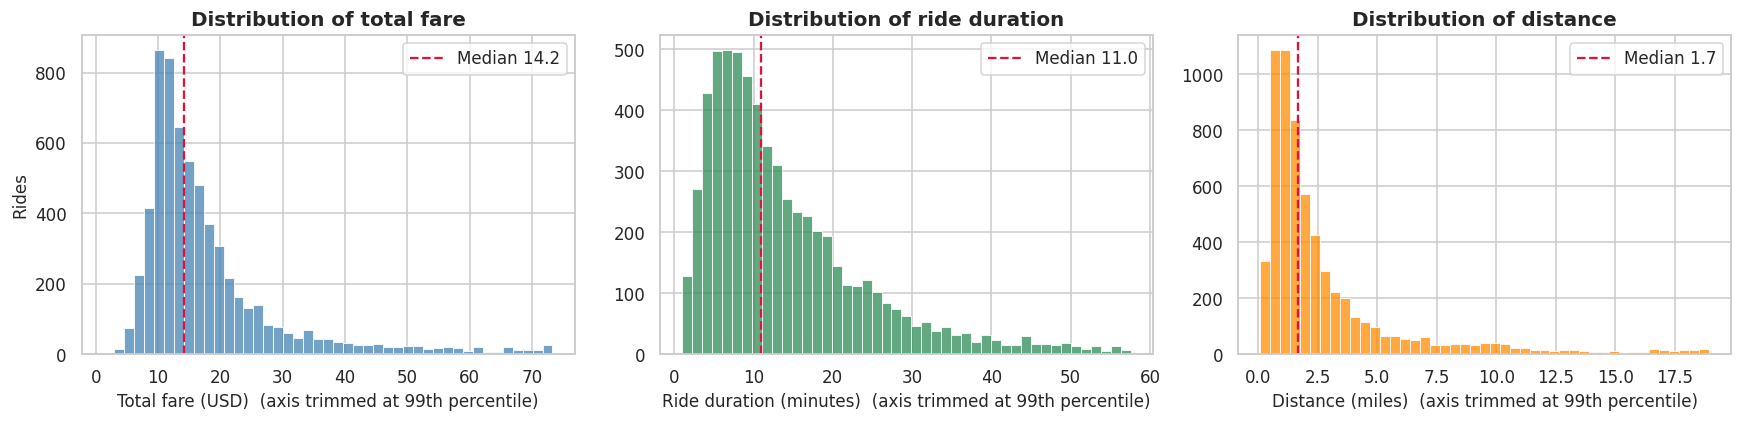

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, label, color in zip(axes, ["total", "duration_min", "distance"],
                                 ["Total fare (USD)", "Ride duration (minutes)", "Distance (miles)"],
                                 ["steelblue", "seagreen", "darkorange"]):
    upper = df[col].quantile(0.99)
    sns.histplot(df.loc[df[col] <= upper, col], bins=45, ax=ax, color=color)
    ax.axvline(df[col].median(), color="crimson", ls="--", label=f"Median {df[col].median():,.1f}")
    ax.set(title=f"Distribution of {label.split(' (')[0].lower()}", xlabel=label + "  (axis trimmed at 99th percentile)", ylabel="Rides" if col == "total" else "")
    ax.legend()
plt.tight_layout()
plt.show()

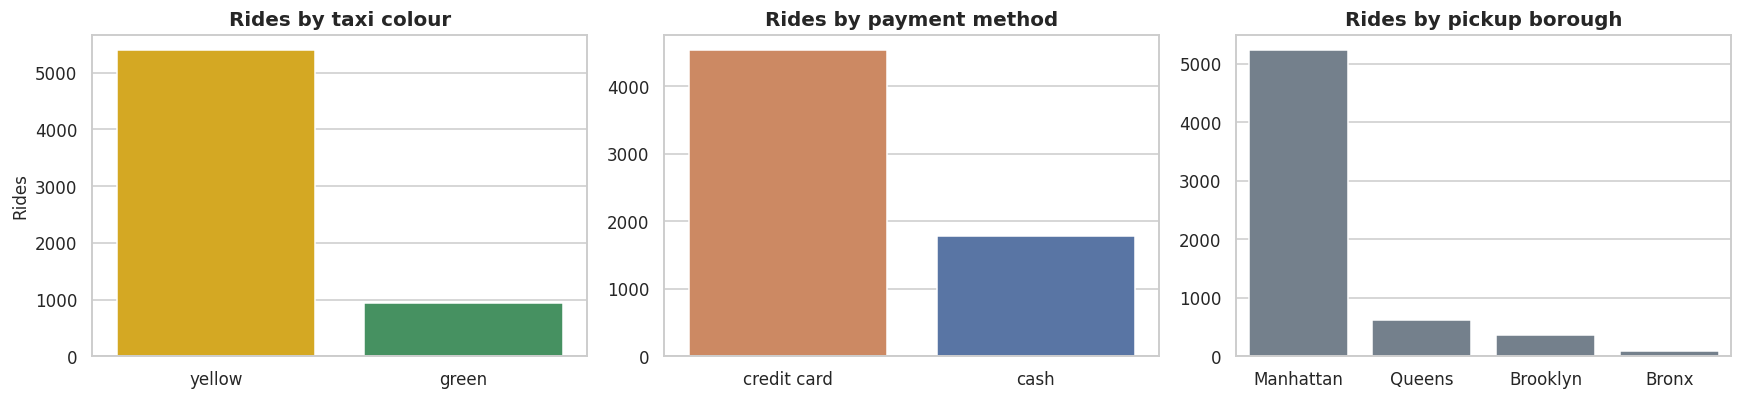

Yellow taxis: 85.0% of rides | Manhattan pickups: 82.7% of rides with a known borough


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.countplot(data=df, x="color", order=["yellow", "green"], hue="color", palette=taxi_palette, legend=False, dodge=False, ax=axes[0])
axes[0].set(title="Rides by taxi colour", xlabel="", ylabel="Rides")
sns.countplot(data=df.dropna(subset=["payment"]), x="payment", hue="payment", palette=payment_palette, legend=False, dodge=False, ax=axes[1])
axes[1].set(title="Rides by payment method", xlabel="", ylabel="")
order = df["pickup_borough"].value_counts().index
sns.countplot(data=df.dropna(subset=["pickup_borough"]), x="pickup_borough", order=order, color="slategray", ax=axes[2])
axes[2].set(title="Rides by pickup borough", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

print(f"Yellow taxis: {(df['color'] == 'yellow').mean():.1%} of rides | Manhattan pickups: {(df['pickup_borough'] == 'Manhattan').sum() / df['pickup_borough'].notna().sum():.1%} of rides with a known borough")

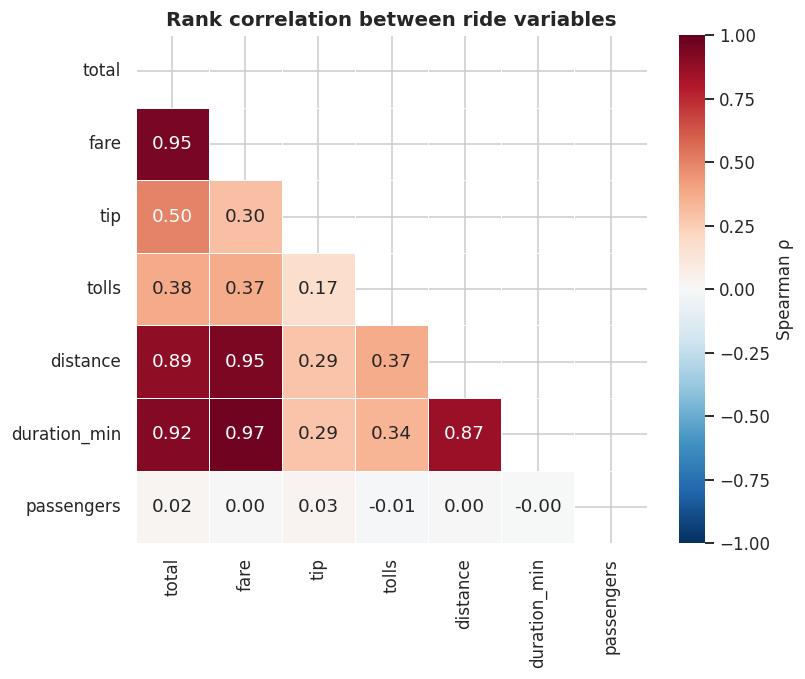

In [10]:
num_cols = ["total", "fare", "tip", "tolls", "distance", "duration_min", "passengers"]
corr = df[num_cols].corr(method="spearman")
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Spearman ρ"})
plt.title("Rank correlation between ride variables")
plt.show()

**Finding.**

- **Typical ride:** median fare about $14, about 11 minutes and about 1.7 miles. All three distributions are right-skewed by a small number of long trips (skewness of total fare about 3).
- **The sample is dominated by yellow taxis (85%) and Manhattan pickups (83% of rides with a known borough).** Comparisons involving green taxis or the outer boroughs rest on much smaller samples.
- **What moves with the total fare:** the rank correlation of `total` with `duration_min` is about 0.92 and with `distance` about 0.89. `tip` (0.50) and `tolls` (0.38) contribute less, and **`passengers` is essentially unrelated to fare (0.02)**, which is expected because fares are metered per trip, not per passenger.

## 5. Question-Driven Analysis

### Q1. How does the total fare differ by payment method?

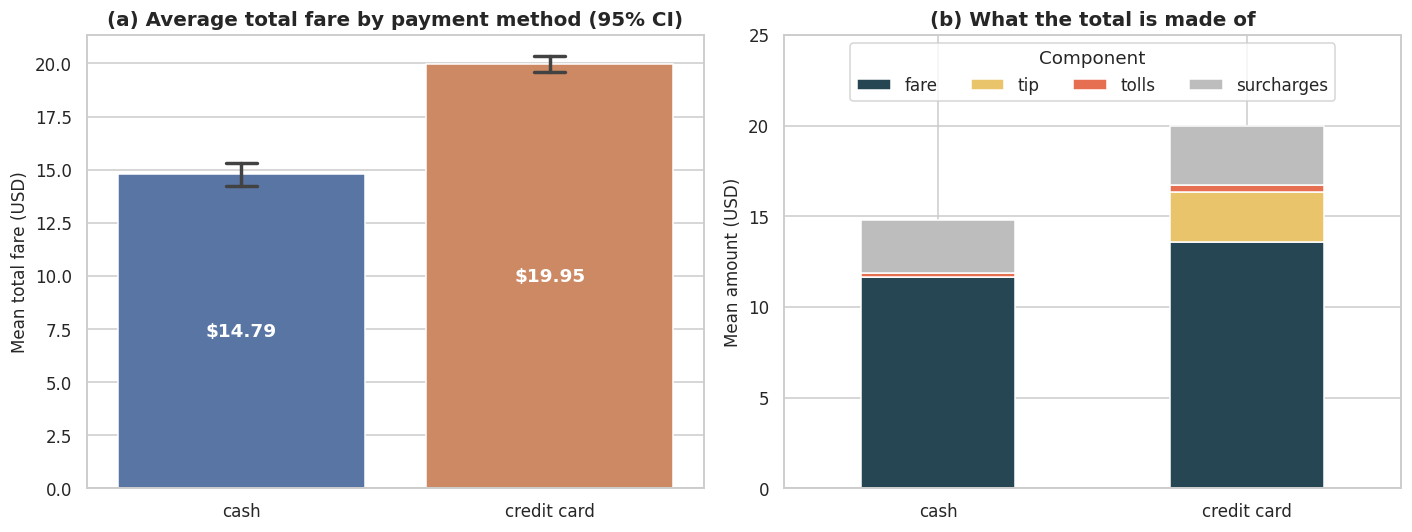

,rides,mean_distance,mean_duration_min,mean_fare,median_fare_per_mile,mean_tip,share_zero_tip
payment,,,,,,,
cash,1780,2.59,12.84,11.68,5.68,0.00,1.00
credit card,4538,3.25,15.18,13.58,5.32,2.77,0.10


Mann-Whitney U, cash vs card, total         : p = 8.78e-110 | medians: cash 11.80 vs card 15.35
Mann-Whitney U, cash vs card, fare          : p = 4.00e-15 | medians: cash 8.50 vs card 9.50
Mann-Whitney U, cash vs card, distance      : p = 6.03e-15 | medians: cash 1.47 vs card 1.75
Mann-Whitney U, cash vs card, fare_per_mile : p = 1.12e-11 | medians: cash 5.68 vs card 5.32


In [11]:
pay = df.dropna(subset=["payment"]).copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pay_order = ["cash", "credit card"]
sns.barplot(data=pay, x="payment", y="total", order=pay_order, hue="payment", palette=payment_palette, legend=False,
            dodge=False, errorbar=("ci", 95), capsize=0.1, ax=axes[0])
axes[0].set(title="(a) Average total fare by payment method (95% CI)", xlabel="", ylabel="Mean total fare (USD)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="$%.2f", label_type="center", color="white", fontweight="bold", fontsize=12)

comp = pay.groupby("payment")[["fare", "tip", "tolls", "surcharges"]].mean().loc[pay_order]
comp.plot(kind="bar", stacked=True, ax=axes[1], rot=0,
          color=["#264653", "#e9c46a", "#e76f51", "#bdbdbd"])
axes[1].set(title="(b) What the total is made of", xlabel="", ylabel="Mean amount (USD)", ylim=(0, 25))
axes[1].legend(title="Component", ncol=4, loc="upper center")
plt.tight_layout()
plt.show()

summary = pay.groupby("payment").agg(
    rides=("total", "size"),
    mean_distance=("distance", "mean"),
    mean_duration_min=("duration_min", "mean"),
    mean_fare=("fare", "mean"),
    median_fare_per_mile=("fare_per_mile", "median"),
    mean_tip=("tip", "mean"),
    share_zero_tip=("tip", lambda s: (s == 0).mean()),
)
display(summary)

cash, card = pay.loc[pay["payment"] == "cash"], pay.loc[pay["payment"] == "credit card"]
for col in ["total", "fare", "distance", "fare_per_mile"]:
    u, p = stats.mannwhitneyu(cash[col], card[col])
    print(f"Mann-Whitney U, cash vs card, {col:<14}: p = {p:.2e} | medians: cash {cash[col].median():.2f} vs card {card[col].median():.2f}")

**Finding.** At face value, credit-card rides cost far more: **$19.95 on average against $14.79 for cash (about $5 or 35% more).** The decomposition shows this is largely not a price difference:

- **Tips.** Card rides average $2.77 in tips and cash rides $0, because cash tips are not recorded. Most of the gap between the two totals is simply this recording difference.
- **Trip length.** Excluding tips, the metered fare is still about $1.90 higher for cards ($13.58 vs $11.68), but card rides are also longer (mean 3.25 vs 2.59 miles; median 1.75 vs 1.47).
- **Price per mile is actually higher for cash** (median $5.68 vs $5.32 per mile). This fits a fixed starting charge being spread over shorter trips, although the data cannot confirm that mechanism.

All four tests are highly significant (p < 1e-10), so the differences are real, but the interpretation is different from "card customers pay more": **`total` understates cash rides, so payment-method comparisons of `total` should not be taken at face value.** For like-for-like comparisons, `fare` is the safer measure.

### Q2. How well do ride duration and distance explain the fare?

The scatter below shows total fare against ride duration (calculated from `pickup` and `dropoff`). Distance is compared as a competing predictor, and `fare` (the metered amount) is compared with `total`, which also contains tips.

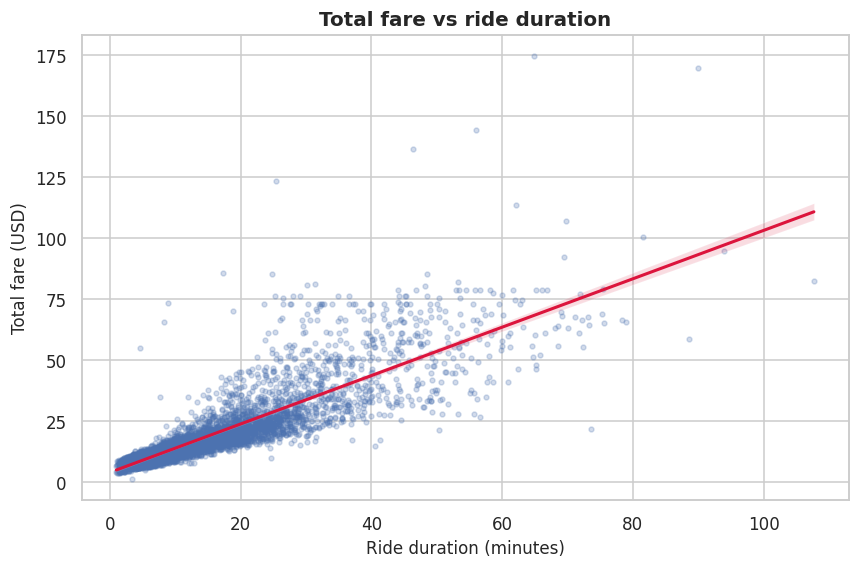

Total fare vs duration: $0.99 per extra minute, intercept $4.09, r = 0.86, R² = 0.73


,R² for total,R² for fare
predictors,,
duration only,0.73,0.79
distance only,0.89,0.92
duration + distance,0.91,0.95



Metered fare model: fare = 2.42 + 2.08 x miles + 0.29 x minutes


In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.regplot(data=df, x="duration_min", y="total", scatter_kws={"alpha": 0.25, "s": 10},
            line_kws={"color": "crimson", "linewidth": 2}, ax=ax)
ax.set(title="Total fare vs ride duration", xlabel="Ride duration (minutes)", ylabel="Total fare (USD)")
plt.show()

res = stats.linregress(df["duration_min"], df["total"])
print(f"Total fare vs duration: ${res.slope:.2f} per extra minute, intercept ${res.intercept:.2f}, r = {res.rvalue:.2f}, R² = {res.rvalue ** 2:.2f}")

r2 = {}
for target in ["total", "fare"]:
    r2[target] = {
        "duration only": smf.ols(f"{target} ~ duration_min", data=df).fit().rsquared,
        "distance only": smf.ols(f"{target} ~ distance", data=df).fit().rsquared,
        "duration + distance": smf.ols(f"{target} ~ duration_min + distance", data=df).fit().rsquared,
    }
display(pd.DataFrame(r2).rename_axis("predictors").add_prefix("R² for "))

meter = smf.ols("fare ~ distance + duration_min", data=df).fit()
print("\nMetered fare model: fare = {:.2f} + {:.2f} x miles + {:.2f} x minutes".format(*meter.params))

**Finding.** Longer rides cost more, at about **$0.99 per extra minute** (intercept $4.09, R² = 0.73), but **distance is a better predictor than duration**:

| Predictors | R² for `total` | R² for `fare` (metered) |
|---|---|---|
| Duration only | 0.73 | 0.79 |
| Distance only | 0.89 | 0.92 |
| Duration + distance | 0.91 | 0.95 |

- Metered fare is described well by **fare ≈ $2.42 + $2.08 per mile + $0.29 per minute** (R² = 0.95), which resembles a metered tariff with a starting charge, a per-mile rate and a small time component.
- Duration adds only 3 points of R² once distance is known, so its apparent power in the scatter comes mostly from being correlated with distance.
- Models of `fare` fit better than models of `total` because tips add unpredictable noise to the total. The scatter also shows the spread widening beyond 30 minutes and a few extreme high-fare rides.

### Q3. Does the fare-duration relationship differ by payment method or taxi colour?

Splitting the previous scatter by payment method (colour) and taxi colour (panels).

color   green             yellow            
payment  cash credit card   cash credit card
rides     386         561   1394        3977 



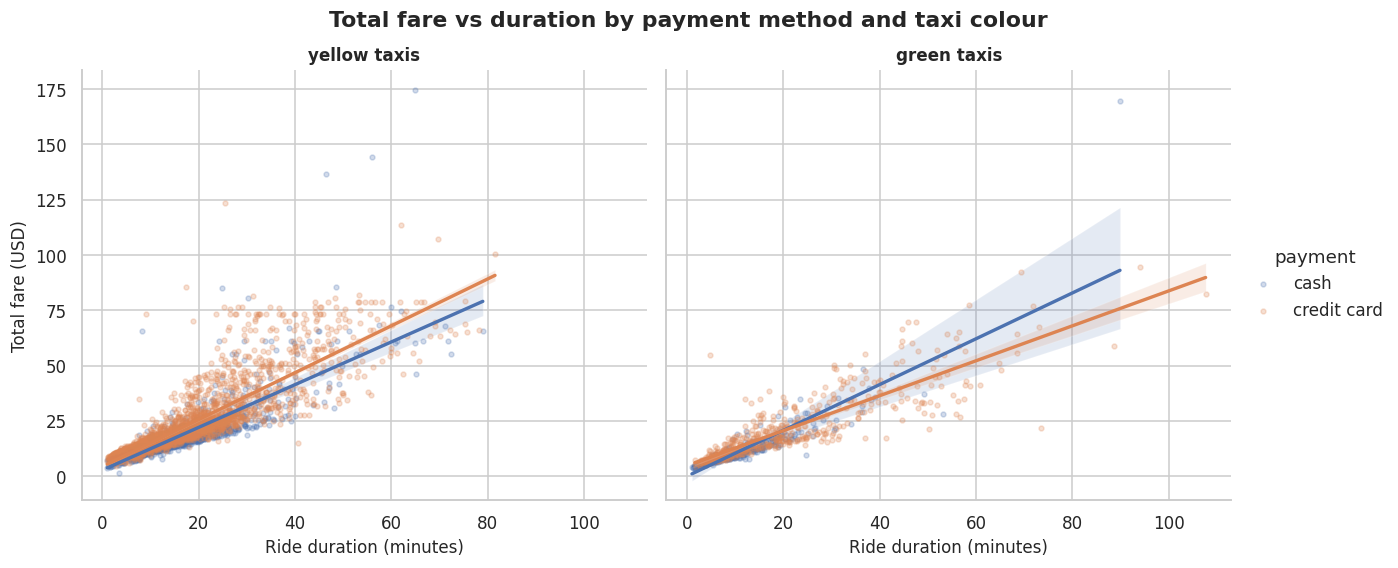

rides  total: $ per min  total: R²  fare: $ per min  \
taxi   payment                                                            
green  cash           386              1.04       0.75             0.97   
       credit card    561              0.79       0.76             0.77   
yellow cash          1394              0.97       0.69             0.91   
       credit card   3977              1.06       0.77             0.86   

                    fare: R²  
taxi   payment                
green  cash             0.79  
       credit card      0.81  
yellow cash             0.70  
       credit card      0.82

In [13]:
pay = df.dropna(subset=["payment"]).copy()
print(pay.groupby(["color", "payment"]).size().rename("rides").to_frame().T.to_string(), "\n")

g = sns.lmplot(data=pay, x="duration_min", y="total", hue="payment", hue_order=["cash", "credit card"], col="color", col_order=["yellow", "green"],
               palette=payment_palette, scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"linewidth": 2.2},
               height=5, aspect=1.15)
g.set_titles("{col_name} taxis")
g.set(xlabel="Ride duration (minutes)", ylabel="Total fare (USD)")
g.figure.suptitle("Total fare vs duration by payment method and taxi colour", y=1.03, fontweight="bold")
plt.show()

rows = []
for (color, payment), grp in pay.groupby(["color", "payment"]):
    t = stats.linregress(grp["duration_min"], grp["total"])
    f = stats.linregress(grp["duration_min"], grp["fare"])
    rows.append({"taxi": color, "payment": payment, "rides": len(grp),
                 "total: $ per min": t.slope, "total: R²": t.rvalue ** 2,
                 "fare: $ per min": f.slope, "fare: R²": f.rvalue ** 2})
pd.DataFrame(rows).set_index(["taxi", "payment"])

**Finding.** The basic pricing relationship is **very similar across payment method and taxi colour**; the main visible difference is a vertical offset, not a different slope.

- Group sizes range from 386 (green, cash) to 3,977 (yellow, credit card) rides.
- Fare slopes per extra minute sit in a fairly narrow band of about $0.77 to $0.97 (total: $0.79 to $1.06), with R² between 0.69 and 0.77 for total fare (0.70 to 0.82 for fare).
- Card lines sit above cash lines mainly because `total` includes tips for card rides only (see Q1).
- The one noticeably different slope is **green taxis paid by card** (about $0.77 per minute of fare vs about $0.97 for green cash). The green-cash line is based on only 386 rides with few long trips, as its wide confidence band shows, so I would not read much into this gap.

Where green and yellow taxis differ substantially is in tipping (Q4), not in how fares scale with time.

### Q4. How do passengers tip, and does tipping differ between yellow and green taxis?

Cash tips are not recorded in this dataset (every cash ride shows a $0 tip), so tipping is analysed for **credit-card rides only**, as a percentage of the metered fare. Payment mix by taxi colour is examined first, because it can distort the raw tip comparison.

,cash (% of rides),credit card (% of rides)
color,,
green,40.80,59.20
yellow,26.00,74.00


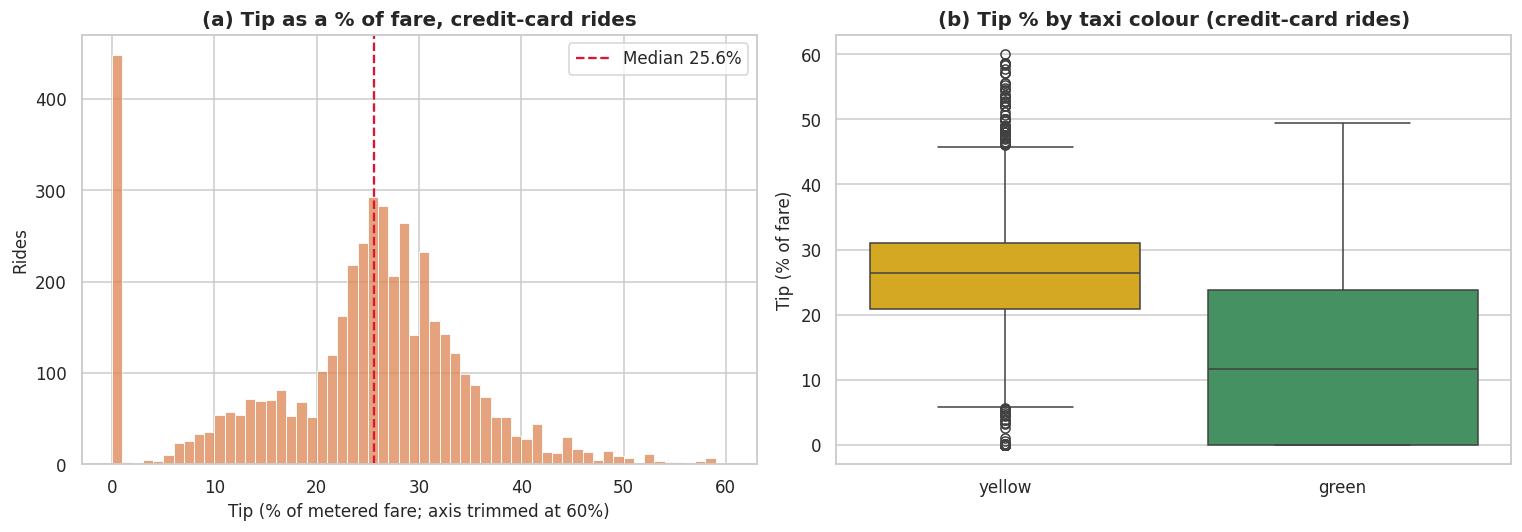

,card_rides,median_tip_pct,mean_tip_pct,share_zero_tip
color,,,,
green,561,11.76,12.95,0.46
yellow,3977,26.33,25.41,0.05


Mann-Whitney U on tip %, yellow vs green (card rides): p = 1.11e-92

Mean tip per ride across ALL rides (including cash): {'green': '$0.82', 'yellow': '$2.18'}


In [14]:
card = df.loc[df["tip_pct"].notna()].copy()

mix = pd.crosstab(pay["color"], pay["payment"], normalize="index") * 100
display(mix.round(1).rename_axis(None, axis=1).add_suffix(" (% of rides)"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(card.loc[card["tip_pct"] <= 60, "tip_pct"], binwidth=1, ax=axes[0], color="#dd8452")
axes[0].axvline(card["tip_pct"].median(), color="crimson", ls="--", label=f"Median {card['tip_pct'].median():.1f}%")
axes[0].set(title="(a) Tip as a % of fare, credit-card rides", xlabel="Tip (% of metered fare; axis trimmed at 60%)", ylabel="Rides")
axes[0].legend()

sns.boxplot(data=card.loc[card["tip_pct"] <= 60], x="color", y="tip_pct", order=["yellow", "green"], hue="color",
            palette=taxi_palette, legend=False, dodge=False, ax=axes[1])
axes[1].set(title="(b) Tip % by taxi colour (credit-card rides)", xlabel="", ylabel="Tip (% of fare)")
plt.tight_layout()
plt.show()

tips = card.groupby("color").agg(card_rides=("tip_pct", "size"), median_tip_pct=("tip_pct", "median"),
                                 mean_tip_pct=("tip_pct", "mean"), share_zero_tip=("tip", lambda s: (s == 0).mean()))
display(tips)

y, gn = card.loc[card["color"] == "yellow", "tip_pct"], card.loc[card["color"] == "green", "tip_pct"]
print(f"Mann-Whitney U on tip %, yellow vs green (card rides): p = {stats.mannwhitneyu(y, gn).pvalue:.2e}")
print("\nMean tip per ride across ALL rides (including cash): ", end="")
print(df.groupby("color")["tip"].mean().map("${:.2f}".format).to_dict())

**Finding.** Tipping differs sharply between the two taxi types:

- **Overall card tipping:** the median tip is **25.6%** of the metered fare (mean 23.9%), with a main cluster between about 20% and 35% and a separate spike of about 10% of card rides with **no tip at all**.
- **Yellow vs green:** median tip on card rides is **26.3% for yellow but only 11.8% for green**, and **46% of green card rides record no tip against 5% for yellow.** The difference is highly significant (Mann-Whitney p < 0.001).
- **Payment mix explains only part of it.** Green taxis have a higher cash share (41% vs 26%), which lowers their average tip per ride ($0.82 vs $2.18 across all rides). But the gap persists among card rides alone, so it cannot be blamed on cash.

The data cannot tell whether green-taxi passengers really tip less or whether tips are captured differently for green taxis (for example, tipping prompts or equipment), so this should be read as a pattern to investigate rather than a conclusion about passenger behaviour.

### Q5. When is demand highest, and how do speeds and fares change through the day?

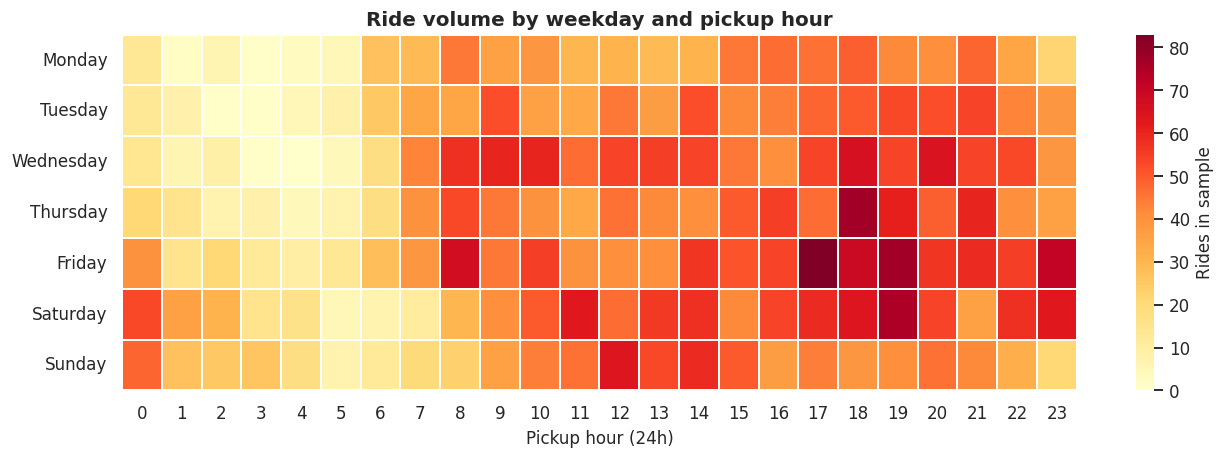

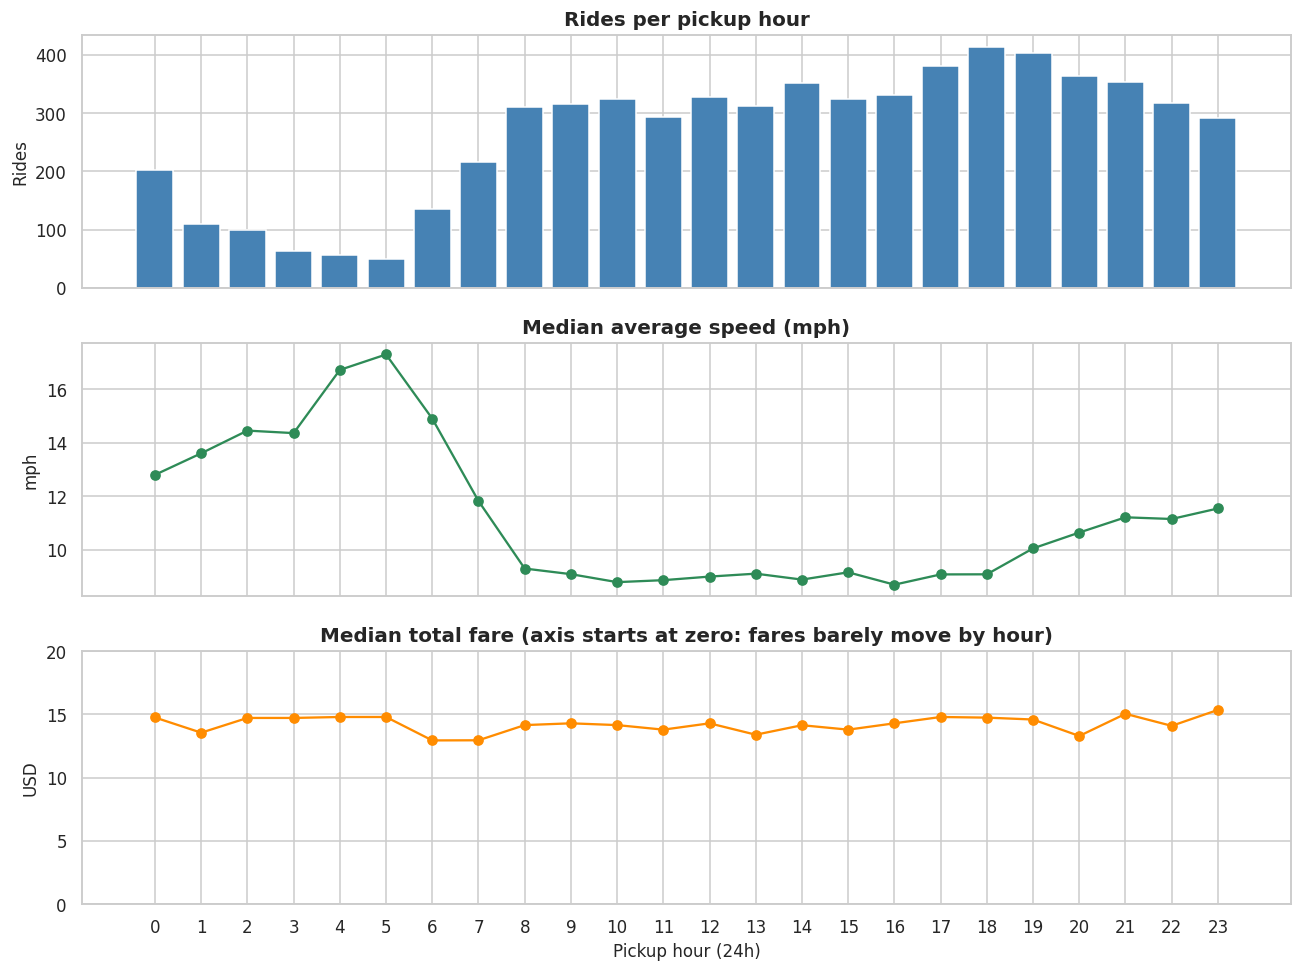

Busiest hour: 18:00 (414 rides) | quietest hour: 5:00 (49 rides)
Slowest median speed: 8.7 mph at 16:00 | fastest: 17.3 mph at 5:00
Kruskal-Wallis, total fare across weekdays: p = 0.001


,rides,median_total,median_duration
weekday,,,
Monday,702,14.30,10.61
Tuesday,812,14.75,11.38
Wednesday,954,14.75,11.36
Thursday,897,14.80,11.88
Friday,1100,14.15,11.27
Saturday,1024,13.80,10.63
Sunday,860,13.55,10.08


In [15]:
heat = df.pivot_table(index="weekday", columns="hour", values="total", aggfunc="size", observed=False).fillna(0)
plt.figure(figsize=(14, 4.2))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.3, cbar_kws={"label": "Rides in sample"})
plt.title("Ride volume by weekday and pickup hour")
plt.xlabel("Pickup hour (24h)")
plt.ylabel("")
plt.show()

hourly = df.groupby("hour").agg(rides=("total", "size"), median_speed=("speed_mph", "median"),
                                median_total=("total", "median"), median_distance=("distance", "median"))

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].bar(hourly.index, hourly["rides"], color="steelblue")
axes[0].set(title="Rides per pickup hour", ylabel="Rides")
axes[1].plot(hourly.index, hourly["median_speed"], marker="o", color="seagreen")
axes[1].set(title="Median average speed (mph)", ylabel="mph")
axes[2].plot(hourly.index, hourly["median_total"], marker="o", color="darkorange")
axes[2].set(title="Median total fare (axis starts at zero: fares barely move by hour)", ylabel="USD", xlabel="Pickup hour (24h)", ylim=(0, 20))
axes[2].set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

busy = hourly["rides"].idxmax()
print(f"Busiest hour: {busy}:00 ({hourly.loc[busy, 'rides']} rides) | quietest hour: {hourly['rides'].idxmin()}:00 ({hourly['rides'].min()} rides)")
print(f"Slowest median speed: {hourly['median_speed'].min():.1f} mph at {hourly['median_speed'].idxmin()}:00 | fastest: {hourly['median_speed'].max():.1f} mph at {hourly['median_speed'].idxmax()}:00")
h, p = stats.kruskal(*[g["total"].values for _, g in df.groupby("weekday", observed=True)])
print(f"Kruskal-Wallis, total fare across weekdays: p = {p:.3f}")
df.groupby("weekday", observed=True).agg(rides=("total", "size"), median_total=("total", "median"), median_duration=("duration_min", "median"))

**Finding.**

- **Volume:** demand is lowest between about 1 and 5 am (49 rides at 5 am) and climbs from 6 am to a plateau of roughly 300 rides per hour through the day. **It peaks at 6 pm (414 rides)** and stays high until about 11 pm. The heatmap shows the very busiest cells on Thursday, Friday and Saturday evenings, and that weekend nights (Saturday and Sunday from midnight to about 2 am, i.e. Friday and Saturday nights) are much busier than weekday nights.
- **Speed:** the median average speed is roughly **9 mph from 8 am to 6 pm** (slowest at 4 pm, 8.7 mph) and almost double that, **17 mph, at 5 am**. Congestion, not the time of day itself, is the likely driver.
- **Fares hardly move by hour.** The median total stays roughly between $13 and $15 all day. Lower speeds do not produce visibly higher median fares, which is consistent with the metered fare being dominated by distance (Q2).
- **Weekdays:** Friday and Saturday are the busiest days (1,100 and 1,024 rides in the sample) and Monday the quietest (702). The Kruskal-Wallis test flags a statistically significant difference in fares by weekday, but the medians only span $13.55 (Sunday) to $14.80 (Thursday), a gap that is small in practical terms.

### Q6. Which boroughs, zones and routes generate the longest and most expensive rides?

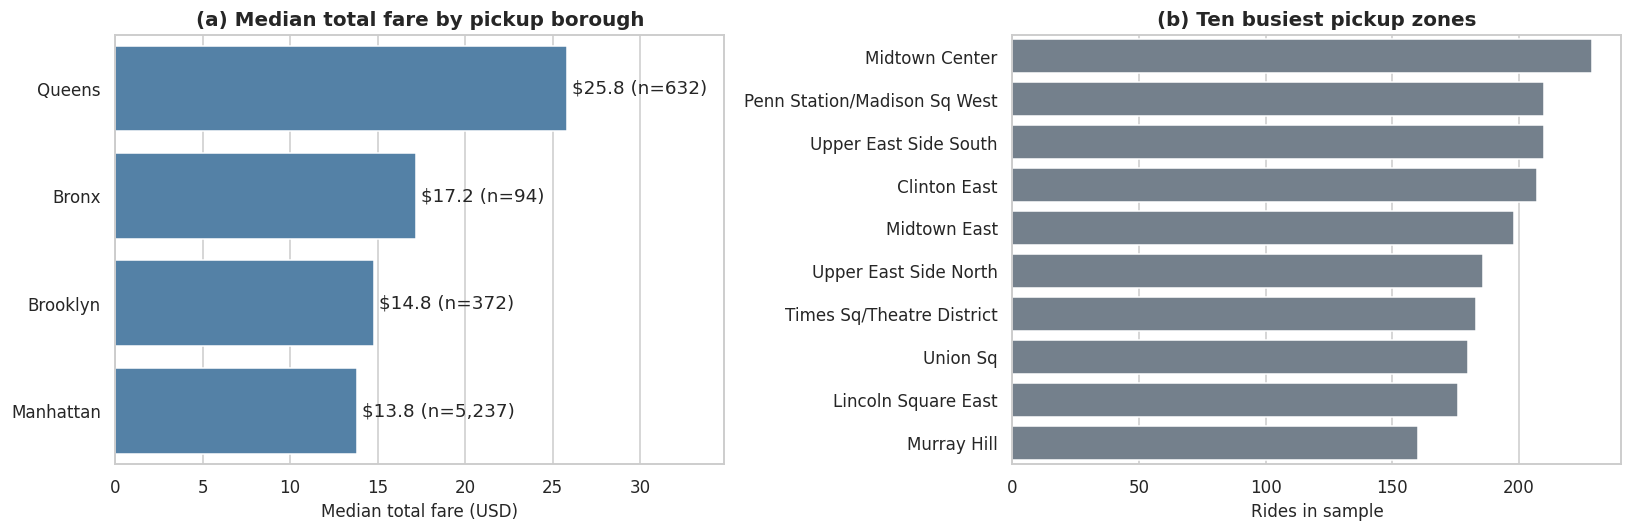

rides  median_distance  median_duration_min  \
pickup_borough dropoff_borough                                                
Manhattan      Manhattan         4855             1.42                 9.72   
Queens         Queens             326             1.94                 9.75   
Brooklyn       Brooklyn           274             1.77                11.10   
Queens         Manhattan          224            10.21                32.48   
Manhattan      Queens             163            10.56                32.08   
               Brooklyn           153             6.14                25.42   
Brooklyn       Manhattan           67             5.48                24.52   
Bronx          Bronx               62             2.92                17.03   
Queens         Brooklyn            62            11.63                32.28   
Manhattan      Bronx               55             6.87                22.72   

                                median_total  
pickup_borough dropoff_borough                
Manhattan      Manhattan               13.55  
Queens         Queens                  11.21  
Brooklyn       Brooklyn                11.30  
Queens         Manhattan               50.46  
Manhattan      Queens                  48.11  
               Brooklyn                30.96  
Brooklyn       Manhattan               27.88  
Bronx          Bronx                   14.30  
Queens         Brooklyn                40.05  
Manhattan      Bronx                   26.80

               distance  total
same_borough                  
cross-borough      9.30  39.66
same borough       1.47  13.30

Cross-borough rides: 12.7% of rides with both boroughs known


In [16]:
geo = df.dropna(subset=["pickup_borough"])
by_borough = geo.groupby("pickup_borough").agg(rides=("total", "size"), median_total=("total", "median"),
                                              median_distance=("distance", "median")).sort_values("median_total", ascending=False)

top_zones = df["pickup_zone"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=by_borough["median_total"], y=by_borough.index, color="steelblue", ax=axes[0])
for i, (borough, row) in enumerate(by_borough.iterrows()):
    axes[0].text(row["median_total"] + 0.3, i, f"${row['median_total']:.1f} (n={int(row['rides']):,})", va="center")
axes[0].set(title="(a) Median total fare by pickup borough", xlabel="Median total fare (USD)", ylabel="")
axes[0].set_xlim(0, by_borough["median_total"].max() * 1.35)

sns.barplot(x=top_zones.values, y=top_zones.index, color="slategray", ax=axes[1])
axes[1].set(title="(b) Ten busiest pickup zones", xlabel="Rides in sample", ylabel="")
plt.tight_layout()
plt.show()

routes = (geo.dropna(subset=["dropoff_borough"])
             .groupby(["pickup_borough", "dropoff_borough"])
             .agg(rides=("total", "size"), median_distance=("distance", "median"),
                  median_duration_min=("duration_min", "median"), median_total=("total", "median"))
             .query("rides >= 30").sort_values("rides", ascending=False))
display(routes)

known = df.dropna(subset=["same_borough"])
print(known.groupby("same_borough")[["distance", "total"]].median().rename(index={True: "same borough", False: "cross-borough"}).round(2).to_string())
print(f"\nCross-borough rides: {(known['same_borough'] == False).mean():.1%} of rides with both boroughs known")

In [17]:
airport = df.groupby("airport_trip").agg(rides=("total", "size"), median_distance=("distance", "median"),
                                          median_total=("total", "median"), share_with_tolls=("has_toll", "mean"))
airport.index = airport.index.map({True: "airport trip", False: "other trips"})
display(airport)

print(df.groupby("has_toll")["total"].agg(["size", "median"]).rename(index={True: "with tolls", False: "no tolls"}).to_string())
print(f"\nAirport trips: {df['airport_trip'].mean():.1%} of rides, {df.loc[df['airport_trip'], 'total'].sum() / df['total'].sum():.1%} of total fare revenue")

,rides,median_distance,median_total,share_with_tolls
airport_trip,,,,
other trips,5949,1.56,13.80,0.02
airport trip,400,10.89,50.30,0.61


            size  median
has_toll                
no tolls    6003   13.80
with tolls   346   54.24

Airport trips: 6.3% of rides, 17.3% of total fare revenue


**Finding.**

- **Geography is Manhattan-centred.** The ten busiest pickup zones are all in Manhattan, led by Midtown Center (229 rides), Penn Station/Madison Sq West and Upper East Side South (210 each).
- **Queens has the highest median fare ($25.8, n = 632), Manhattan the lowest ($13.8).** Queens rides are not expensive in themselves: Queens to Queens trips have a median fare of $11.21. The premium comes from trips that **leave** Queens (median $50.46 to Manhattan, 224 rides), including airport runs.
- **Route type matters most.** Only **12.7% of rides cross a borough boundary**, but they have a median distance of 9.3 miles and median fare of $39.66, roughly 3 times the $13.30 for same-borough rides. Manhattan to Manhattan alone accounts for 4,855 rides at a median of 1.4 miles and $13.55.
- **Airports and tolls:** airport trips are only 6.3% of rides (400) but have a median fare of **$50.30** against $13.80 for other trips, 61% of them include tolls (vs 2%), and they generate **17.3% of total fare revenue**. Rides with any toll (346) have a median total of $54.24.

### Q7. How concentrated is revenue?

Ranking rides by total fare shows how much of the total revenue comes from a small share of trips, and what those trips have in common.

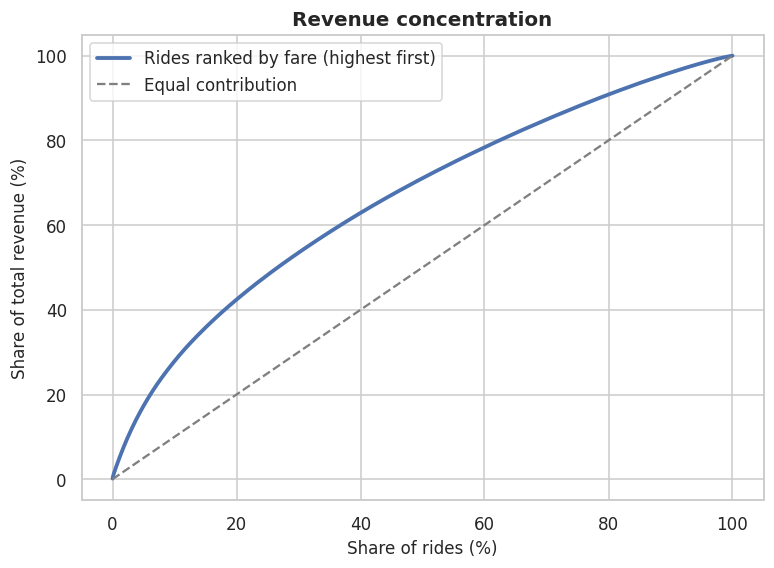

Top   1% of rides (63) generate 4.5% of revenue
Top   5% of rides (317) generate 17.3% of revenue
Top  10% of rides (634) generate 27.9% of revenue
Top  20% of rides (1,269) generate 42.4% of revenue


,rides,median_total,median_distance,median_duration_min,airport_share,toll_share,cross_borough_share,card_share
segment,,,,,,,,
Other 90%,5715,13.55,1.50,10.03,0.01,0.00,0.05,0.70
Top 10% by fare,634,47.47,10.98,35.95,0.53,0.52,0.84,0.86


In [18]:
ranked = df.sort_values("total", ascending=False).reset_index(drop=True)
ranked["cum_rides"] = (ranked.index + 1) / len(ranked)
ranked["cum_revenue"] = ranked["total"].cumsum() / ranked["total"].sum()

plt.figure(figsize=(8, 5.5))
plt.plot(ranked["cum_rides"] * 100, ranked["cum_revenue"] * 100, lw=2.5, label="Rides ranked by fare (highest first)")
plt.plot([0, 100], [0, 100], color="gray", ls="--", label="Equal contribution")
plt.xlabel("Share of rides (%)")
plt.ylabel("Share of total revenue (%)")
plt.title("Revenue concentration")
plt.legend()
plt.show()

for share in [0.01, 0.05, 0.10, 0.20]:
    k = int(len(ranked) * share)
    print(f"Top {share:>4.0%} of rides ({k:,}) generate {ranked.loc[:k - 1, 'total'].sum() / ranked['total'].sum():.1%} of revenue")

ranked["segment"] = np.where(ranked["cum_rides"] <= 0.10, "Top 10% by fare", "Other 90%")
profile = ranked.groupby("segment").agg(
    rides=("total", "size"), median_total=("total", "median"), median_distance=("distance", "median"),
    median_duration_min=("duration_min", "median"), airport_share=("airport_trip", "mean"),
    toll_share=("has_toll", "mean"), cross_borough_share=("same_borough", lambda s: (s == False).sum() / s.notna().sum()),
    card_share=("payment", lambda s: (s == "credit card").sum() / s.notna().sum()),
)
profile

**Finding.** Revenue is moderately, not extremely, concentrated: **the top 10% of rides (634 trips) generate 27.9% of total revenue** and the top 20% generate 42.4%. The top 1% account for 4.5%.

The high-value segment has a very clear profile: median fare **$47.47** (vs $13.55), median distance 11.0 miles (vs 1.5) and median duration 36 minutes (vs 10). **53% are airport trips and 84% cross a borough boundary**, against 1% and 5% in the rest of the data. The card share is also higher (86% vs 70%), but that partly reflects tips being recorded for cards, since `total` includes them.

In short, a small group of long airport and inter-borough trips contributes disproportionately, while the majority of rides are short, local Manhattan trips at a typical $13 to $14.

## 6. Key Insights

1. **Payment-method comparisons of `total` are distorted by recording.** Cards appear to cost about $5 more, but cash tips are not recorded, and card rides are also longer. Per mile, cash rides are slightly *more* expensive.
2. **Distance predicts fare better than duration.** Metered fare is well approximated by $2.42 + $2.08 per mile + $0.29 per minute (R² 0.95); duration adds little once distance is known.
3. **The fare-duration relationship is stable** across payment methods and taxi colours (roughly $0.8 to $1.0 of fare per extra minute).
4. **Green taxis record far lower tips** than yellow taxis on card rides (median 11.8% vs 26.3%; 46% of rides with no tip vs 5%), a gap not explained by payment mix and possibly influenced by how tips are captured.
5. **Demand peaks at 6 pm; congestion roughly halves speeds** in the daytime (about 9 mph vs 17 mph at 5 am), yet median fares stay flat across the day.
6. **Long trips drive the money:** 12.7% of rides cross a borough boundary and cost about 3 times as much as local trips; airport trips are 6% of rides but 17% of revenue.
7. **The top 10% of rides generate about 28% of revenue**, and over half of those are airport trips.
8. **Data quality:** 1.3% of rides were implausible and removed; `passengers` has no relationship with fare.

## 7. Conclusion

The dataset tells a consistent story: **taxi fares are about distance and route type, not payment method, passenger count or time of day.** Most rides are short Manhattan trips at $13 to $14, while a small minority of long airport and inter-borough trips contribute a disproportionate share of revenue. The most important analytical lesson is how recording conventions (untracked cash tips, fixed fees inside `total`) can create differences that are not real, and how decomposing `total` into its components resolves them.

**Limitations**

- The data covers a single month (March 2019) and 6,433 rides, a sample rather than all trips, with yellow taxis and Manhattan heavily over-represented.
- Cash tips are not recorded, so no conclusion about total tipping behaviour can be drawn. Tip analysis is restricted to card rides.
- Differences between green and yellow taxis may reflect zones served, trip mix or how data is captured, not just rider behaviour. All findings are associations, not causal claims.
- Speed is derived from straight distance and elapsed time, and the flagged-and-removed rides are defined by simple thresholds.

**Possible next steps:** compare weekday and hour effects after controlling for distance, model the tip decision separately from the tip amount, and map zone-level demand and revenue.